In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import spacy
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import torch
from transformers import AutoTokenizer, AutoModel



In [2]:
df = pd.read_csv("../data/potential-talents - Aspiring human resources - seeking human resources.csv")

df.head()

,id,job_title,location,connection,fit
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500+,NaN
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,People Development Coordinator at Ryan,"Denton, Texas",500+,NaN
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN


In [3]:
df = df.drop("fit",axis=1)

In [4]:
df.head()

,id,job_title,location,connection
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500+
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44
3,4,People Development Coordinator at Ryan,"Denton, Texas",500+
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+


In [5]:
print(df["connection"].unique())

['85' '500+ ' '44' '1' '61' '2' '390' '57' '82' '5' '7' '16' '212' '409'
 '52' '455' '174' '268' '50' '4' '40' '18' '349' '155' '39' '64' '9' '415'
 '19' '71' '48' '103' '49']


In [6]:
df['connection'] = df['connection'].replace("500+ ","500")

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          104 non-null    int64 
 1   job_title   104 non-null    object
 2   location    104 non-null    object
 3   connection  104 non-null    object
dtypes: int64(1), object(3)
memory usage: 3.4+ KB


In [8]:
df = df.drop_duplicates(subset=['job_title'])

In [9]:
df.head(60)


,id,job_title,location,connection
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44
3,4,People Development Coordinator at Ryan,"Denton, Texas",500
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500
5,6,Aspiring Human Resources Specialist,Greater New York City Area,1
6,7,Student at Humber College and Aspiring Human R...,Kanada,61
7,8,HR Senior Specialist,San Francisco Bay Area,500
9,10,Seeking Human Resources HRIS and Generalist Po...,Greater Philadelphia Area,500
10,11,Student at Chapman University,"Lake Forest, California",2


In [10]:
df.columns

Index(['id', 'job_title', 'location', 'connection'], dtype='object')

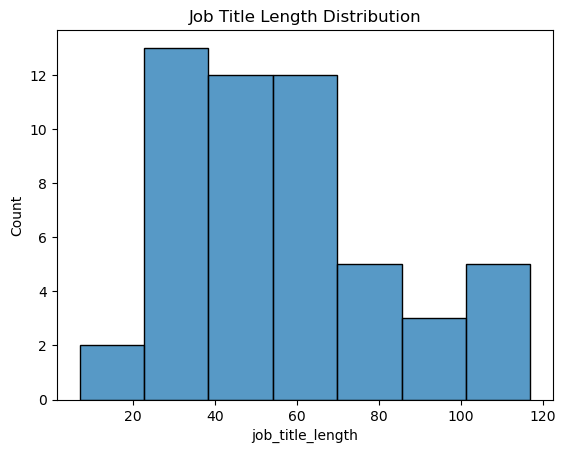

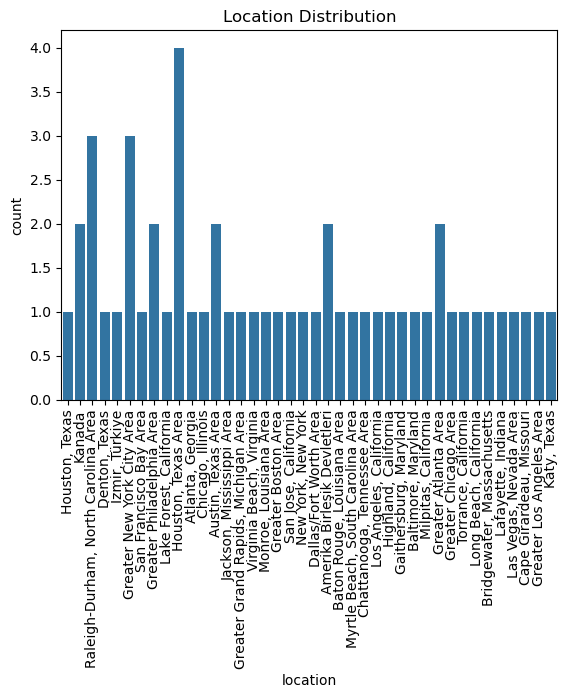

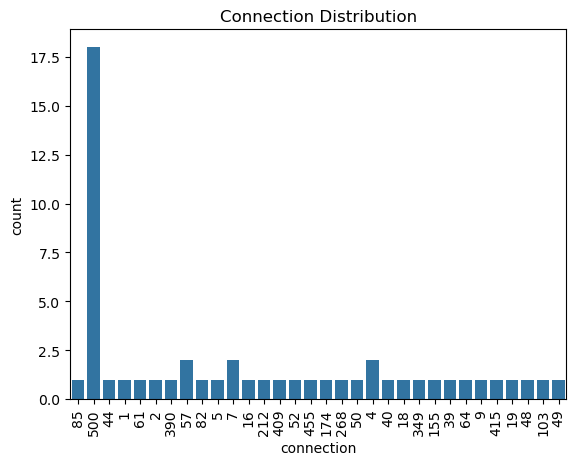

In [11]:
# Count the lengh of the title
df["job_title_length"] = df["job_title"].str.len()
sns.histplot(df["job_title_length"])
plt.title("Job Title Length Distribution")
plt.show()

# Use count plot for location and connection based on 1 variable and count
sns.countplot(
    data = df,
    x = "location"
)
plt.xticks(rotation=90)
plt.title("Location Distribution")
plt.show()


sns.countplot(
    data= df,
    x = "connection"
)
plt.title("Connection Distribution")
plt.xticks(rotation=90)
plt.show()

In [12]:
nlp = spacy.load("en_core_web_sm")

df['job_title'] = df['job_title'].astype("str").str.strip()

In [13]:
#!python -m spacy download en_core_web_sm

The idea is to build a function and apply it to each row in the job title column. The function tokenizes the text, removes punctuation and stop words, converts the words to lowercase, lemmatizes them, and returns the cleaned words as a list for each row in the job_title and return the join str becasue each model will use its own tokenization method.

In [14]:
def clean_title(x):
    doc = nlp(x)

    clean_text = []

    for token in doc:
        if not token.is_stop and not token.is_punct:
            clean_text.append(token.lemma_.lower())

    return " ".join(clean_text)

In [15]:
df["clean_job_title"] = df["job_title"].apply(clean_title)

In [16]:
df['clean_job_title']

0      2019 c.t. bauer college business graduate magn...
1      native english teacher epik english program korea
2                  aspiring human resources professional
3                    people development coordinator ryan
4           advisory board member celal bayar university
5                    aspiring human resources specialist
6      student humber college aspiring human resource...
7                                   hr senior specialist
9         seek human resources hris generalist positions
10                            student chapman university
11     svp chro marketing communications csr officer ...
12     human resources coordinator intercontinental b...
26     aspiring human resources management student se...
27                      seek human resources opportunity
65     experienced retail manager aspire human resour...
66      human resources staffing recruiting professional
67                  human resources specialist luxottica
68     director human resources

In [17]:
measure_rank_1 = "aspiring human resources" 
measure_rank_2 =  "seeking human resources"

In [18]:
print(clean_title("aspiring human resources professional"))

aspire human resource professional


^\x00-\x7F is a pattern for non english characters

In [19]:
df[df["job_title"].str.contains(r"[^\x00-\x7F]", regex=True, na=False)]

,id,job_title,location,connection,job_title_length,clean_job_title


In [20]:
df[df["location"].str.contains(r"[^\x00-\x7F]", regex=True, na=False)]

,id,job_title,location,connection,job_title_length,clean_job_title
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500,47,advisory board member celal bayar university
77,78,Human Resources Generalist at Schwan's,Amerika Birleşik Devletleri,500,38,human resources generalist schwan
93,94,Seeking Human Resources Opportunities. Open t...,Amerika Birleşik Devletleri,415,70,seek human resources opportunity open travel...


replace works on the entire word for one char then it is str.replace

In [21]:
df['location'] = df['location'].str.replace("ü","u")
df['location'] = df['location'].str.replace("ş","s")
df['location'] = df['location'].str.replace("İ","I")

In [22]:
df[df["location"].str.contains(r"[^\x00-\x7F]", regex=True, na=False)]

,id,job_title,location,connection,job_title_length,clean_job_title


BoW  is defined as how many times does the word appear?
TF-IDF is defined as how important/distinctive is this word compared with the rest of the dataset?

In [23]:
# BOW method 
# You fit and transform on the column
# you only transform the y1 and y2
vectorizer_bow = CountVectorizer()
X = vectorizer_bow.fit_transform(df['clean_job_title'])
y1 = vectorizer_bow.transform([measure_rank_1])
y2 = vectorizer_bow.transform([measure_rank_2])

In [24]:
score_1 = cosine_similarity(y1, X)
score_2 = cosine_similarity(y2, X)

In [84]:
df["similarity_1_bow"] = score_2.flatten()
df[df["similarity_1_bow"]>0.4][["job_title", "similarity_1_bow"]].sort_values(
    by="similarity_1_bow",
    ascending=False
).head(10)

,job_title,similarity_1_bow
98,Seeking Human Resources Position,0.905610
27,Seeking Human Resources Opportunities,0.904017
93,Seeking Human Resources Opportunities. Open t...,0.848398
73,Human Resources Professional,0.797023
2,Aspiring Human Resources Professional,0.794786
5,Aspiring Human Resources Specialist,0.774733
67,Human Resources Specialist at Luxottica,0.773057
9,Seeking Human Resources HRIS and Generalist Po...,0.772474
88,Director Human Resources at EY,0.761400
66,"Human Resources, Staffing and Recruiting Profe...",0.747984


In [83]:
df["similarity_2_bow"] = score_2.flatten()
df[df["similarity_2_bow"]>0.4][["job_title", "similarity_2_bow"]].sort_values(
    by="similarity_2_bow",
    ascending=False
).head(10)

,job_title,similarity_2_bow
98,Seeking Human Resources Position,0.905610
27,Seeking Human Resources Opportunities,0.904017
93,Seeking Human Resources Opportunities. Open t...,0.848398
73,Human Resources Professional,0.797023
2,Aspiring Human Resources Professional,0.794786
5,Aspiring Human Resources Specialist,0.774733
67,Human Resources Specialist at Luxottica,0.773057
9,Seeking Human Resources HRIS and Generalist Po...,0.772474
88,Director Human Resources at EY,0.761400
66,"Human Resources, Staffing and Recruiting Profe...",0.747984


In [ ]:
# Tfidf method
vectorizer_tfidf = TfidfVectorizer()
X = vectorizer_tfidf.fit_transform(df['clean_job_title'])
y1 = vectorizer_tfidf.transform([measure_rank_1])
y2 = vectorizer_tfidf.transform([measure_rank_2])

score_1 = cosine_similarity(y1, X)
score_2 = cosine_similarity(y2, X)

In [82]:
df["similarity_1_tfidf"] = score_2.flatten()
df[df["similarity_1_tfidf"]>0.4][["job_title", "similarity_1_tfidf"]].sort_values(
    by="similarity_1_tfidf",
    ascending=False
).head(10)

,job_title,similarity_1_tfidf
98,Seeking Human Resources Position,0.905610
27,Seeking Human Resources Opportunities,0.904017
93,Seeking Human Resources Opportunities. Open t...,0.848398
73,Human Resources Professional,0.797023
2,Aspiring Human Resources Professional,0.794786
5,Aspiring Human Resources Specialist,0.774733
67,Human Resources Specialist at Luxottica,0.773057
9,Seeking Human Resources HRIS and Generalist Po...,0.772474
88,Director Human Resources at EY,0.761400
66,"Human Resources, Staffing and Recruiting Profe...",0.747984


In [81]:
df["similarity_2_tfidf"] = score_2.flatten()
df[df["similarity_2_tfidf"]>0.4][["job_title", "similarity_2_tfidf"]].sort_values(
    by="similarity_2_tfidf",
    ascending=False
).head(10)

,job_title,similarity_2_tfidf
98,Seeking Human Resources Position,0.905610
27,Seeking Human Resources Opportunities,0.904017
93,Seeking Human Resources Opportunities. Open t...,0.848398
73,Human Resources Professional,0.797023
2,Aspiring Human Resources Professional,0.794786
5,Aspiring Human Resources Specialist,0.774733
67,Human Resources Specialist at Luxottica,0.773057
9,Seeking Human Resources HRIS and Generalist Po...,0.772474
88,Director Human Resources at EY,0.761400
66,"Human Resources, Staffing and Recruiting Profe...",0.747984


In [30]:
#%pip install gensim
import gensim.downloader as api
model = api.load('glove-wiki-gigaword-100')

Each word has a GloVe vector → average all word vectors → get one vector representing the entire job title.

In [31]:
# apply has the tendency to work on the rows automatically 
def get_title_vector(row):
    words = row.split()

    vectors = []

    for word in words:
        if word in model:
            vectors.append(model[word])

    return np.mean(vectors, axis=0)

In [32]:
df['vector_for_modeling'] = df["clean_job_title"].apply(get_title_vector)
y1_vector = get_title_vector(measure_rank_1)
y2_vector = get_title_vector(measure_rank_2)

In [33]:
X_glove = np.vstack(df["vector_for_modeling"])
# to make it work you need to use vstack function
score_1 = cosine_similarity(
    y1_vector.reshape(1, -1),
    X_glove
)

score_2 = cosine_similarity(
    y2_vector.reshape(1, -1),
    X_glove
)


In [ ]:
df["similarity_1_glove"] = score_2.flatten()
# turns a multi-dimensional NumPy array into a one-dimensional array
df[df["similarity_1_glove"]>0.4][["job_title", "similarity_1_glove"]].sort_values(
    by="similarity_1_glove",
    ascending=False
).head(10)

,job_title,similarity_1_glove
98,Seeking Human Resources Position,0.905610
27,Seeking Human Resources Opportunities,0.904017
93,Seeking Human Resources Opportunities. Open t...,0.848398
73,Human Resources Professional,0.797023
2,Aspiring Human Resources Professional,0.794786
5,Aspiring Human Resources Specialist,0.774733
67,Human Resources Specialist at Luxottica,0.773057
9,Seeking Human Resources HRIS and Generalist Po...,0.772474
88,Director Human Resources at EY,0.761400
66,"Human Resources, Staffing and Recruiting Profe...",0.747984


In [ ]:
df["similarity_2_glove"] = score_2.flatten()
# turns a multi-dimensional NumPy array into a one-dimensional array
df[df["similarity_2_glove"]>0.4][["job_title", "similarity_2_glove"]].sort_values(
    by="similarity_2_glove",
    ascending=False
).head(10)




,job_title,similarity
27,Seeking Human Resources Opportunities,0.959400
98,Seeking Human Resources Position,0.951002
72,"Aspiring Human Resources Manager, seeking inte...",0.933817
9,Seeking Human Resources HRIS and Generalist Po...,0.912854
73,Human Resources Professional,0.903358
87,Human Resources Management Major,0.902130
93,Seeking Human Resources Opportunities. Open t...,0.895333
5,Aspiring Human Resources Specialist,0.870710
100,Human Resources Generalist at Loparex,0.860519
80,Senior Human Resources Business Partner at Hei...,0.860115


In [36]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased")

def get_title_vector_bert(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True
    )
# pt is py_torch, truncation for fitting what the model allow in size, padding makes the size the same
    with torch.no_grad():
        outputs = bert(**inputs)


    vector = outputs.last_hidden_state.mean(dim=1)

    return vector.squeeze().numpy()
# make the tensor a numpy array with one dimension 
df['bert_for_modeling'] = df["clean_job_title"].apply(get_title_vector_bert)
y1_vector = get_title_vector(measure_rank_1)
y2_vector = get_title_vector(measure_rank_2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [79]:
X_bert = np.vstack(df["bert_for_modeling"])

y1_vector = get_title_vector_bert(measure_rank_1)
y2_vector = get_title_vector_bert(measure_rank_2)

score_1 = cosine_similarity(
    y1_vector.reshape(1, -1),
    X_bert
)

score_2 = cosine_similarity(
    y2_vector.reshape(1, -1),
    X_bert
)

df["similarity_1_bert"] = score_2.flatten()

df[df["similarity_1_bert"]>0.4][["job_title", "similarity_1_bert"]].sort_values(
    by="similarity_1_bert",
    ascending=False
).head(10)


,job_title,similarity_1_bert
98,Seeking Human Resources Position,0.905610
27,Seeking Human Resources Opportunities,0.904017
93,Seeking Human Resources Opportunities. Open t...,0.848398
73,Human Resources Professional,0.797023
2,Aspiring Human Resources Professional,0.794786
5,Aspiring Human Resources Specialist,0.774733
67,Human Resources Specialist at Luxottica,0.773057
9,Seeking Human Resources HRIS and Generalist Po...,0.772474
88,Director Human Resources at EY,0.761400
66,"Human Resources, Staffing and Recruiting Profe...",0.747984


In [78]:
df["similarity_2_bert"] = score_2.flatten()

df[df["similarity_2_bert"]>0.4][["job_title", "similarity_2_bert"]].sort_values(
    by="similarity_2_bert",
    ascending=False
).head(10)

,job_title,similarity_2_bert
98,Seeking Human Resources Position,0.820647
27,Seeking Human Resources Opportunities,0.811510
5,Aspiring Human Resources Specialist,0.780673
2,Aspiring Human Resources Professional,0.772700
9,Seeking Human Resources HRIS and Generalist Po...,0.763636
73,Human Resources Professional,0.727105
66,"Human Resources, Staffing and Recruiting Profe...",0.696157
72,"Aspiring Human Resources Manager, seeking inte...",0.678746
6,Student at Humber College and Aspiring Human R...,0.653782
99,Aspiring Human Resources Manager | Graduating ...,0.652151


In [39]:
tokenizer = AutoTokenizer.from_pretrained(
    "sentence-transformers/all-MiniLM-L6-v2"
)

sbert = AutoModel.from_pretrained(
    "sentence-transformers/all-MiniLM-L6-v2"
)


def get_title_vector_sbert(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True
    )

    with torch.no_grad():
        outputs = sbert(**inputs)

    # Token embeddings
    token_embeddings = outputs.last_hidden_state

    # Attention mask
    attention_mask = inputs["attention_mask"]

    # Expand mask to same dimensions as embeddings
    mask = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

    # Mean pooling, ignoring padding tokens
    vector = (token_embeddings * mask).sum(dim=1) / mask.sum(dim=1)

    return vector.squeeze().numpy()


df["sbert_for_modeling"] = df["clean_job_title"].apply(
    get_title_vector_sbert
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [77]:
s_bert = np.vstack(df["sbert_for_modeling"])

y1_vector = get_title_vector_sbert(measure_rank_1)
y2_vector = get_title_vector_sbert(measure_rank_2)

score_1 = cosine_similarity(
    y1_vector.reshape(1, -1),
    s_bert
)

score_2 = cosine_similarity(
    y2_vector.reshape(1, -1),
    s_bert
)

df["similarity_1_sbert"] = score_2.flatten()

df[df["similarity_1_sbert"]>0.4][["job_title", "similarity_1_sbert"]].sort_values(
    by="similarity_1_sbert",
    ascending=False
).head(10)

,job_title,similarity_1_sbert
98,Seeking Human Resources Position,0.820647
27,Seeking Human Resources Opportunities,0.811510
5,Aspiring Human Resources Specialist,0.780673
2,Aspiring Human Resources Professional,0.772700
9,Seeking Human Resources HRIS and Generalist Po...,0.763636
73,Human Resources Professional,0.727105
66,"Human Resources, Staffing and Recruiting Profe...",0.696157
72,"Aspiring Human Resources Manager, seeking inte...",0.678746
6,Student at Humber College and Aspiring Human R...,0.653782
99,Aspiring Human Resources Manager | Graduating ...,0.652151


In [76]:
df["similarity_2_sbert"] = score_2.flatten()

df[df["similarity_2_sbert"]>0.4][["job_title", "similarity_2_sbert"]].sort_values(
    by="similarity_2_sbert",
    ascending=False
).head(10)

,job_title,similarity_2_sbert
27,Seeking Human Resources Opportunities,0.526061
98,Seeking Human Resources Position,0.518350
72,"Aspiring Human Resources Manager, seeking inte...",0.516380
26,Aspiring Human Resources Management student se...,0.513578
2,Aspiring Human Resources Professional,0.510476
69,"Retired Army National Guard Recruiter, office ...",0.507946
5,Aspiring Human Resources Specialist,0.500634
66,"Human Resources, Staffing and Recruiting Profe...",0.498590
81,Aspiring Human Resources Professional | An ene...,0.493667
99,Aspiring Human Resources Manager | Graduating ...,0.492588


In [87]:
def similarity_hist(var):
    df[var].hist(bins=20)
    plt.xlabel("Cosine similarity")
    plt.ylabel("Number of candidates")
    plt.title("Similarity Score Distribution")
    plt.show()

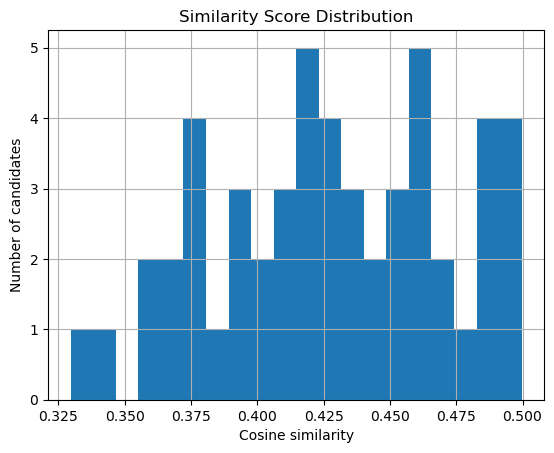

In [89]:
similarity_hist("similarity_1_5e")

In [90]:
def similarity_elbow(var):
    scores = (
        df[var]
        .sort_values(ascending=False)
        .reset_index(drop=True)
    )

    plt.plot(scores)
    plt.xlabel("Candidate rank")
    plt.ylabel("Cosine similarity")
    plt.title("Ranked Similarity Scores")
    plt.show()

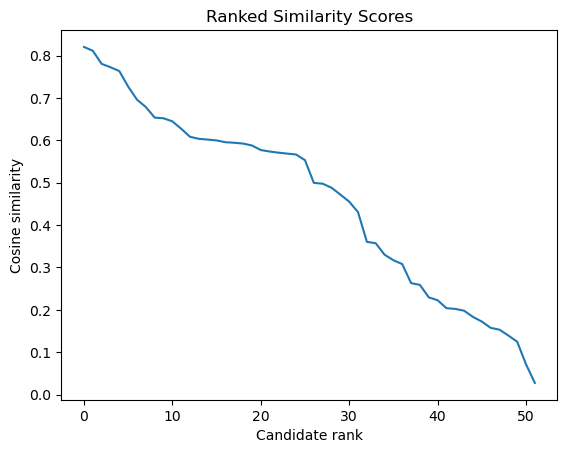

In [91]:
similarity_elbow("similarity_1_sbert")

In [42]:
tokenizer = AutoTokenizer.from_pretrained(
    "intfloat/e5-small-v2"
)

e5 = AutoModel.from_pretrained(
    "intfloat/e5-small-v2"
)


def get_title_vector_e5(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True
    )

    with torch.no_grad():
        outputs = e5(**inputs)

    # Token embeddings
    token_embeddings = outputs.last_hidden_state

    # Attention mask
    attention_mask = inputs["attention_mask"]

    # Expand mask to same dimensions as embeddings
    mask = attention_mask.unsqueeze(-1).expand(
        token_embeddings.size()
    ).float()

    # Mean pooling
    vector = (token_embeddings * mask).sum(dim=1) / mask.sum(dim=1)

    return vector.squeeze().numpy()


df["e5_for_modeling"] = df["clean_job_title"].apply(
    get_title_vector_e5
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [43]:
X_e5 = np.vstack(df["e5_for_modeling"])

y1_vector = get_title_vector_e5(measure_rank_1)
y2_vector = get_title_vector_e5(measure_rank_2)

In [75]:
score_1 = cosine_similarity(
    y1_vector.reshape(1, -1),
    X_e5
)

df["similarity_1_5e"] = score_1.flatten()

df[df["similarity_1_5e"]>0.4][["job_title", "similarity_1_5e"]].sort_values(
    by="similarity_1_5e",
    ascending=False
).head(10)

,job_title,similarity_1_5e
26,Aspiring Human Resources Management student se...,0.499655
2,Aspiring Human Resources Professional,0.498409
71,Business Management Major and Aspiring Human R...,0.494278
72,"Aspiring Human Resources Manager, seeking inte...",0.491426
27,Seeking Human Resources Opportunities,0.490649
5,Aspiring Human Resources Specialist,0.488460
99,Aspiring Human Resources Manager | Graduating ...,0.483702
81,Aspiring Human Resources Professional | An ene...,0.483642
66,"Human Resources, Staffing and Recruiting Profe...",0.477689
6,Student at Humber College and Aspiring Human R...,0.470359


In [74]:
score_2 = cosine_similarity(
    y2_vector.reshape(1, -1),
    X_e5
)

df["similarity_2_5e"] = score_2.flatten()

df[df["similarity_2_5e"]>0.4][["job_title", "similarity_2_5e"]].sort_values(
    by="similarity_2_5e",
    ascending=False
).head(10)

,job_title,similarity_2_5e
27,Seeking Human Resources Opportunities,0.526061
98,Seeking Human Resources Position,0.518350
72,"Aspiring Human Resources Manager, seeking inte...",0.516380
26,Aspiring Human Resources Management student se...,0.513578
2,Aspiring Human Resources Professional,0.510476
69,"Retired Army National Guard Recruiter, office ...",0.507946
5,Aspiring Human Resources Specialist,0.500634
66,"Human Resources, Staffing and Recruiting Profe...",0.498590
81,Aspiring Human Resources Professional | An ene...,0.493667
99,Aspiring Human Resources Manager | Graduating ...,0.492588


In [46]:
tokenizer = AutoTokenizer.from_pretrained(
    "BAAI/bge-small-en-v1.5"
)

bge = AutoModel.from_pretrained(
    "BAAI/bge-small-en-v1.5"
)


def get_title_vector_bge(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True
    )

    with torch.no_grad():
        outputs = bge(**inputs)

    # Token embeddings
    token_embeddings = outputs.last_hidden_state

    # Attention mask
    attention_mask = inputs["attention_mask"]

    # Expand mask to same dimensions as embeddings
    mask = attention_mask.unsqueeze(-1).expand(
        token_embeddings.size()
    ).float()

    # Mean pooling
    vector = (token_embeddings * mask).sum(dim=1) / mask.sum(dim=1)

    return vector.squeeze().numpy()


df["bge_for_modeling"] = df["clean_job_title"].apply(
    get_title_vector_bge
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [47]:
X_bge = np.vstack(df["bge_for_modeling"])

y1_vector = get_title_vector_bge(measure_rank_1)
y2_vector = get_title_vector_bge(measure_rank_2)

In [67]:
score_1 = cosine_similarity(
    y1_vector.reshape(1, -1),
    X_bge
)

df["similarity_1_bge"] = score_1.flatten()
# Chain the filtering and sorting together
df[df["similarity_1_bge"] > 0.4][["job_title", "similarity_1_bge"]].sort_values(
    by="similarity_1_bge",
    ascending=False
).head(10)

,job_title,similarity_1_bge
2,Aspiring Human Resources Professional,0.925080
5,Aspiring Human Resources Specialist,0.887798
27,Seeking Human Resources Opportunities,0.881803
72,"Aspiring Human Resources Manager, seeking inte...",0.851041
71,Business Management Major and Aspiring Human R...,0.830688
98,Seeking Human Resources Position,0.818461
26,Aspiring Human Resources Management student se...,0.815158
81,Aspiring Human Resources Professional | An ene...,0.813060
75,Aspiring Human Resources Professional | Passio...,0.811294
66,"Human Resources, Staffing and Recruiting Profe...",0.788736


In [66]:
score_2 = cosine_similarity(
    y2_vector.reshape(1, -1),
    X_bge
)

df["similarity_2_bge"] = score_2.flatten()

df[df["similarity_2_bge"] > 0.4][["job_title", "similarity_2_bge"]].sort_values(
    by="similarity_2_bge",
    ascending=False
).head(10)

,job_title,similarity_2_bge
27,Seeking Human Resources Opportunities,0.933537
98,Seeking Human Resources Position,0.913805
9,Seeking Human Resources HRIS and Generalist Po...,0.820881
72,"Aspiring Human Resources Manager, seeking inte...",0.807461
2,Aspiring Human Resources Professional,0.803960
66,"Human Resources, Staffing and Recruiting Profe...",0.794418
5,Aspiring Human Resources Specialist,0.790454
93,Seeking Human Resources Opportunities. Open t...,0.780189
73,Human Resources Professional,0.768290
75,Aspiring Human Resources Professional | Passio...,0.752817


Among the evaluated embedding approaches, E5 produced the most relevant job-title rankings. This is consistent with E5's retrieval-oriented training, which is specifically designed to represent semantically related texts close together in the embedding space.